# DFT analysis of monolayer and bilayer hBN

Ground-state (QuantumESPRESSO, PBE) calculations for the first benchmark of the project (`docs/04_benchmark_systems.md`):
bilayer hBN computed explicitly vs monolayer hBN with the second layer treated as an effective substrate
(Notes, Sec. 2). The **monolayer** is the reference both for the layer and for the "substrate"; the **bilayer**
(stackings AA' and AB) is the explicit reference.

Rule of this notebook: monolayer and bilayers share the **same** lattice constant, cell height, energy cutoff and
k grids, so that explicit and effective calculations differ only by the method (effect of the substrate, not of
the computational setup).

Choices (user, 2026-11-11):
- SG15 ONCV PBE scalar-relativistic pseudopotentials (`../pseudos`, version 1.2, no NLCC), no spin-orbit.
- Fixed in-plane lattice constant, the same for all systems: experimental value of bulk hBN, a = 2.504 Å (a PBE scan
  of the monolayer is kept only as a check).
- Fixed interlayer distance d = 3.33 Å (as in Guo et al., PRB 102, 205113 (2020)); PBE does not bind the layers.
  An optional DFT-D3 scan is a check only.
- Geometry along z: bilayer centred at z = 0 (layers at z = ±d/2). For the effective scheme ("layer" = top layer,
  "substrate" = bottom layer) the monolayer is also computed **in the exact position of each layer of each
  bilayer** (`ML_bot`, `ML_top_AA1`, `ML_top_AB`): chi0 of layer and substrate then come directly from Yambo, with
  no rotation/translation of the databases. How the yambo slab cutoff is centred with respect to the cell origin
  is still to be checked on the Lumen source before the GW step.

## How to run
- ismhpc only (driven by a Claude Code session or Jupyter on the frontend); runs go through slurm (`all12h`), with
  the QE environment loaded by `qe_module`. At most 2 nodes at a time for this project (user, 2026-11-11): the
  runs are 1-node jobs and each Dataset uses `num_tasks=2` (fewer if other jobs are running).
- Each section starts with the cell that defines its calculator and run folder: sections are independent.
- All runs are appended with `skip=True` (the default of the calculator): cells can be re-executed safely, runs
  with existing results are not recomputed.
- Run folder: `DFT_analysis/` (not tracked in git).

In [1]:
# useful to autoreload the module without restarting the kernel
%load_ext autoreload
%autoreload 2

In [2]:
from mppi import InputFiles as I, Calculators as C, Datasets as D, Parsers as P, Utilities as U
from mppi.Calculators import Tools
from mppi.Datasets import PostProcessing as PP
from mppi.Utilities import Constants as Const
from mppi.Utilities import LatticeUtils as LL
import matplotlib.pyplot as plt
import numpy as np
import os

In [3]:
# Calculator factory for ismhpc (32 cores per node; many MPI tasks are better for pw.x)
module = '/home/dalessandro/module_script/qe_module'

def qe_code(nodes=1, partition='all12h', time='11:59:00', ntasks_per_node=16, cpus_per_task=2, omp_num_threads=2):
    rr = C.RunRules(scheduler='slurm', partition=partition, memory='125000', time=time,
                    nodes=nodes, ntasks_per_node=ntasks_per_node, cpus_per_task=cpus_per_task,
                    omp_num_threads=omp_num_threads, pre_processing=module)
    return C.QeCalculator(rr, activate_BeeOND=True)

## Lattice and atomic positions

We use the hexagonal lattice of QuantumESPRESSO (`ibrav=4`):
$$
a_1 = a(1,0,0) \, ,\quad a_2 = a(-\tfrac{1}{2},\tfrac{\sqrt{3}}{2},0) \, ,\quad a_3 = a(0,0,\tfrac{c}{a})
$$
with $c$ the cell height (layer(s) + vacuum), $\mathrm{celldm(3)} = c/a$. Reciprocal vectors in units of $2\pi/a$:
$b_1 = (1,\tfrac{1}{\sqrt{3}},0)$, $b_2 = (0,\tfrac{2}{\sqrt{3}},0)$; high-symmetry points
$M = (0,\tfrac{1}{\sqrt{3}},0)$, $K = (\tfrac{1}{3},\tfrac{1}{\sqrt{3}},0)$.

The three in-plane sites of the honeycomb lattice (cartesian, units of $a$):
$$
S_A = (0,\tfrac{1}{\sqrt{3}}) \;[\text{crystal } (\tfrac13,\tfrac23)] \, ,\quad
S_B = (\tfrac12,\tfrac{1}{2\sqrt{3}}) \;[\text{crystal } (\tfrac23,\tfrac13)] \, ,\quad
S_C = (0,0) \;[\text{hexagon centre}]
$$
- Bottom layer (common to both bilayers): B on $S_A$, N on $S_B$ at $z=-d/2$.
- Bilayer AA' (stacking of bulk hBN): top layer N on $S_A$, B on $S_B$ at $z=+d/2$ (B over N and N over B). The top
  layer is the bottom one **rotated by 180°** about z; the bilayer has an inversion centre at the midpoint (D3d):
  the two layers are equivalent, no dipole.
- Bilayer AB (Bernal, parallel stacking): top layer B on $S_B$ (over the bottom N), N on $S_C$ (over a hexagon
  centre). The top layer is the bottom one **rigidly translated** in the plane; no inversion and no horizontal
  mirror (C3v): the layers are not equivalent and there is a small out-of-plane dipole (sliding ferroelectricity of
  parallel-stacked hBN). This is a ground-state interface effect NOT contained in the effective scheme. To check
  against the AB variant used by Guo et al. before the comparison.

Monolayers: `ML` (convergence studies) = `ML_bot` = the bottom layer alone; `ML_top_AA1` and `ML_top_AB` = the top
layer of each bilayer alone. Their DFT energies and bands are identical (same crystal, moved/rotated); they differ
in the plane-wave phases of the databases used later by Yambo.

In [4]:
pseudo_dir = '../../pseudos'   # relative to the run folder DFT_analysis/, where pw.x runs
B_pseudo = 'B_ONCV_PBE-1.2.upf'
N_pseudo = 'N_ONCV_PBE-1.2.upf'

Bohr = 1./Const.Bohr_to_Angstrom   # bohr per angstrom (Constants gives the conversion factor bohr -> angstrom)

alat_ang = 2.504              # experimental in-plane lattice constant of bulk hBN (angstrom)
alat = alat_ang*Bohr          # in bohr (celldm(1))
d_ang = 3.33                  # interlayer distance (angstrom)
alat, alat_ang, d_ang

(4.731873875401624, 2.504, 3.33)

In [5]:
SA = np.array([0., 1./np.sqrt(3.)])
SB = np.array([1./2., 1./(2*np.sqrt(3.))])
SC = np.array([0., 0.])

def hbn_positions(system, alat_ang=alat_ang, d_ang=d_ang):
    # Atomic positions in units of alat for the bilayers 'AA1' (AA'), 'AB' and the monolayers 'ML' (= 'ML_bot'),
    # 'ML_top_AA1', 'ML_top_AB' (each layer of the bilayers alone, in its own position)
    zt, zb = d_ang/2/alat_ang, -d_ang/2/alat_ang   # top and bottom layer heights (units of alat)
    def at(name, site, z): return [name, np.array([site[0], site[1], z])]
    layers = {'bot': [at('B', SA, zb), at('N', SB, zb)],
              'top_AA1': [at('N', SA, zt), at('B', SB, zt)],
              'top_AB': [at('B', SB, zt), at('N', SC, zt)]}
    if system in ['ML', 'ML_bot']: return layers['bot']
    if system == 'ML_top_AA1': return layers['top_AA1']
    if system == 'ML_top_AB':  return layers['top_AB']
    if system == 'AA1': return layers['bot'] + layers['top_AA1']
    if system == 'AB':  return layers['bot'] + layers['top_AB']
    raise ValueError('unknown system %s' % system)

systems = ['ML_bot', 'ML_top_AA1', 'ML_top_AB', 'AA1', 'AB']
for s in systems: print(s, hbn_positions(s))

ML_bot [['B', array([ 0.        ,  0.57735027, -0.6649361 ])], ['N', array([ 0.5       ,  0.28867513, -0.6649361 ])]]
ML_top_AA1 [['N', array([0.        , 0.57735027, 0.6649361 ])], ['B', array([0.5       , 0.28867513, 0.6649361 ])]]
ML_top_AB [['B', array([0.5       , 0.28867513, 0.6649361 ])], ['N', array([0.       , 0.       , 0.6649361])]]
AA1 [['B', array([ 0.        ,  0.57735027, -0.6649361 ])], ['N', array([ 0.5       ,  0.28867513, -0.6649361 ])], ['N', array([0.        , 0.57735027, 0.6649361 ])], ['B', array([0.5       , 0.28867513, 0.6649361 ])]]
AB [['B', array([ 0.        ,  0.57735027, -0.6649361 ])], ['N', array([ 0.5       ,  0.28867513, -0.6649361 ])], ['B', array([0.5       , 0.28867513, 0.6649361 ])], ['N', array([0.       , 0.       , 0.6649361])]]


Check of the geometry: positions in the xy and xz planes (a few cells).

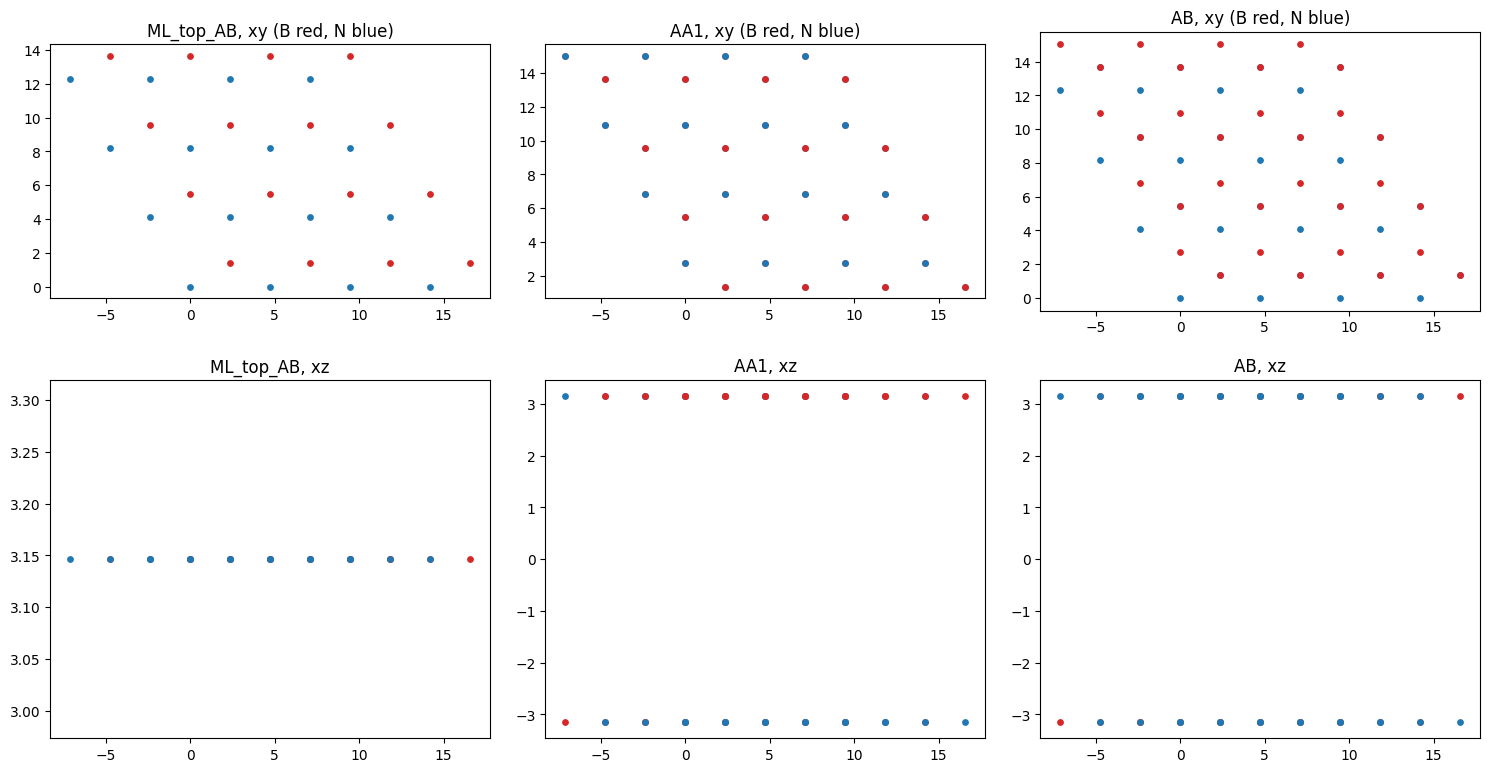

In [6]:
c_plot = 40.0  # bohr, only for this plot
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(15, 8))
for i, s in enumerate(['ML_top_AB', 'AA1', 'AB']):
    lattice = alat*np.array([[1,0,0],[-1./2.,np.sqrt(3)/2.,0],[0,0,c_plot/alat]])
    atoms = [[name, alat*pos] for name, pos in hbn_positions(s)]
    positions = LL.build_lattice(lattice, atoms, 4, 4, 1)
    for pos in positions:
        col = 'tab:red' if pos[0] == 'B' else 'tab:blue'
        ax[0, i].scatter(pos[1], pos[2], color=col, s=15)
        ax[1, i].scatter(pos[1], pos[3], color=col, s=15)
    ax[0, i].set_title('%s, xy (B red, N blue)' % s); ax[0, i].set_aspect('equal')
    ax[1, i].set_title('%s, xz' % s)
plt.tight_layout()

## Base input

`build_input(system, ...)` builds the scf input of a system with the given parameters: no spin-orbit, fixed
occupations (insulator). Number of bands: 4 occupied per layer, 4 empty per layer in the scf.

In [7]:
nocc = {s: (8 if s in ['AA1', 'AB'] else 4) for s in ['ML'] + systems}   # occupied bands (8 valence electrons per layer)

def build_input(system, ecut, kpoints, c, alat=alat, conv_thr=1e-8, nbnd=None):
    # scf input; atomic positions in units of alat, computed for the fixed alat_ang (also when alat is scanned)
    inp = I.PwInput()
    inp.set_scf(force_symmorphic=True, conv_thr=conv_thr)
    inp.set_num_bnds(nbnd if nbnd is not None else 2*nocc[system])
    inp.set_pseudo_dir(pseudo_dir=pseudo_dir)
    inp.add_atom(atom='B', pseudo_name=B_pseudo, mass=10.811)
    inp.add_atom(atom='N', pseudo_name=N_pseudo, mass=14.007)
    pos = hbn_positions(system, alat_ang=alat/Bohr)   # z positions rescaled so that d stays 3.33 A
    inp.set_atoms_number(len(pos))
    inp.set_atomic_positions(pos, type='alat')
    inp.set_lattice(ibrav=4, celldm1=alat, celldm3=c/alat)
    inp.set_energy_cutoff(ecut)
    inp.set_kpoints(type='automatic', points=[kpoints, kpoints, 1])
    return inp

def gap_gamma(r, system):
    # gap at Gamma (first k point of the automatic grid)
    ev = r.get_evals()[0]
    return ev[nocc[system]] - ev[nocc[system]-1]

# starting guesses (to be replaced by the converged values below)
ecut_0 = 80     # Ry
k_0 = 12
c_0 = 40.0      # bohr (cell height)
build_input('AA1', ecut_0, k_0, c_0)

{'control': {'calculation': "'scf'",
  'verbosity': "'high'",
  'prefix': "'pwscf'",
  'outdir': "'./'",
  'pseudo_dir': "'../../pseudos'"},
 'system': {'force_symmorphic': '.true.',
  'nbnd': 16,
  'ntyp': 2,
  'nat': 4,
  'ibrav': 4,
  'celldm(1)': 4.731873875401624,
  'celldm(3)': 8.453310686900958,
  'ecutwfc': 80},
 'electrons': {'diago_full_acc': '.false.', 'conv_thr': 1e-08},
 'ions': {},
 'cell': {},
 'atomic_species': {'B': [10.811, 'B_ONCV_PBE-1.2.upf'],
  'N': [14.007, 'N_ONCV_PBE-1.2.upf']},
 'atomic_positions': {'type': 'alat',
  'values': [['B', array([ 0.        ,  0.57735027, -0.6649361 ])],
   ['N', array([ 0.5       ,  0.28867513, -0.6649361 ])],
   ['N', array([0.        , 0.57735027, 0.6649361 ])],
   ['B', array([0.5       , 0.28867513, 0.6649361 ])]]},
 'kpoints': {'type': 'automatic', 'values': ([12, 12, 1], [0.0, 0.0, 0.0])},
 'cell_parameters': {}}

## Monolayer: convergence

### Energy cutoff and k grid
Control quantities: total energy, gap (`get_gap`: direct and indirect), gap at $\Gamma$. Grids multiple of 3 contain
$K$.

In [8]:
run_dir = 'DFT_analysis'
code = qe_code()

Initialize a QuantumESPRESSO calculator with scheduler slurm


In [9]:
kvalues = [9, 12, 15, 18]
ecut = [50, 60, 70, 80, 90, 100]

study = D.Dataset(run_dir=run_dir, num_tasks=2)
for k in kvalues:
    for e in ecut:
        idd = {'system': 'ML', 'ecut': e, 'k': k}
        name = D.name_from_id(idd)
        inp = build_input('ML', e, k, c_0)
        inp.set_prefix(name)
        study.append_run(id=idd, input=inp, runner=code, name=name)
study.set_postprocessing_function(PP.pw_parse_data)
len(study.ids)

Initialize a Dataset with 2 parallel tasks


24

In [10]:
results = study.run()

Run the selection [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23] with the parallel task_groups [[0, 1], [2, 3], [4, 5], [6, 7], [8, 9], [10, 11], [12, 13], [14, 15], [16, 17], [18, 19], [20, 21], [22, 23]] 

Run the task [0, 1] 


Skip the run of

ecut_50-k_9-system_ML

Skip the run of

ecut_60-k_9-system_ML

Task [0, 1] ended 
 
Run the task [2, 3] 


... (51 outputs left out)

ecut_90-k_18-system_ML

Skip the run of

ecut_100-k_18-system_ML

Task [22, 23] ended 
 


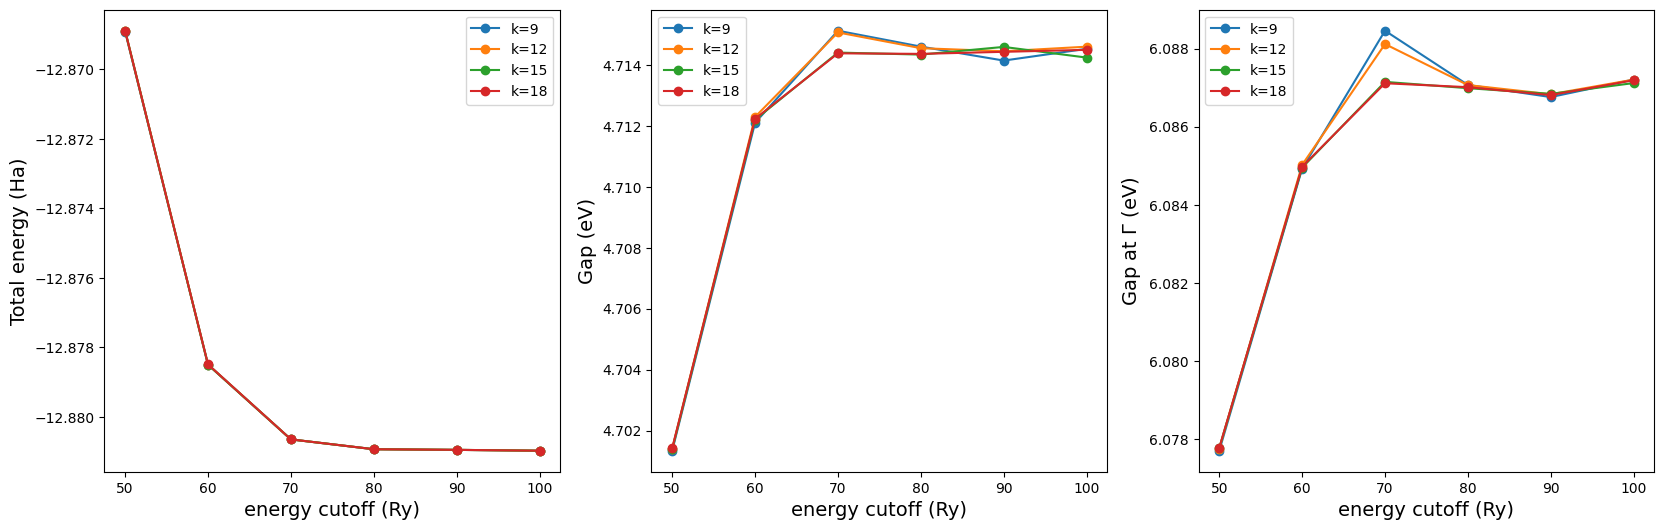

In [11]:
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(20, 6))
for k in kvalues:
    data = study.fetch_results(id={'k': k})
    ax[0].plot(ecut, [d.energy for d in data], 'o-', label='k=%s' % k)
    ax[1].plot(ecut, [d.get_gap(verbose=False)['gap'] for d in data], 'o-', label='k=%s' % k)
    ax[2].plot(ecut, [gap_gamma(d, 'ML') for d in data], 'o-', label='k=%s' % k)
for a, yl in zip(ax, ['Total energy (Ha)', 'Gap (eV)', r'Gap at $\Gamma$ (eV)']):
    a.set_xlabel('energy cutoff (Ry)', size=14); a.set_ylabel(yl, size=14); a.legend()

Result (2026-11-11): at 80 Ry the total energy is within 0.1 mHa of the 100 Ry value and the gaps within 1 meV; the
k grid changes the gaps by less than 1 meV from 9x9 on (insulator). PBE gap of the monolayer: 4.714 eV, direct at K;
gap at $\Gamma$ 6.087 eV. We choose

In [12]:
ecut_conv = 80   # Ry
k_conv = 12

### Lattice constant (check only)
PBE equilibrium lattice constant of the monolayer, to know how far it is from the fixed experimental value. It is
NOT used in the following.

In [13]:
alat_span = np.linspace(-2, 2, 9)   # percentage variation

study = D.Dataset(run_dir=run_dir, num_tasks=2)
for a_span in alat_span:
    idd = {'system': 'ML', 'alat_span': a_span}
    name = D.name_from_id(idd)
    inp = build_input('ML', ecut_conv, k_conv, c_0, alat=alat*(1+a_span/100))
    inp.set_prefix(name)
    study.append_run(id=idd, input=inp, runner=code, name=name)
study.set_postprocessing_function(PP.pw_get_energy)

Initialize a Dataset with 2 parallel tasks


In [14]:
results = study.run()

Run the selection [0, 1, 2, 3, 4, 5, 6, 7, 8] with the parallel task_groups [[0, 1], [2, 3], [4, 5], [6, 7], [8]] 

Run the task [0, 1] 


Skip the run of

alat_span_-2.0-system_ML

Skip the run of

alat_span_-1.5-system_ML

Task [0, 1] ended 
 
Run the task [2, 3] 


... (14 outputs left out)

Task [6, 7] ended 
 
Run the task [8] 


Skip the run of

alat_span_2.0-system_ML

Task [8] ended 
 


PBE equilibrium a = 2.5083 angstrom (fixed value 2.5040)


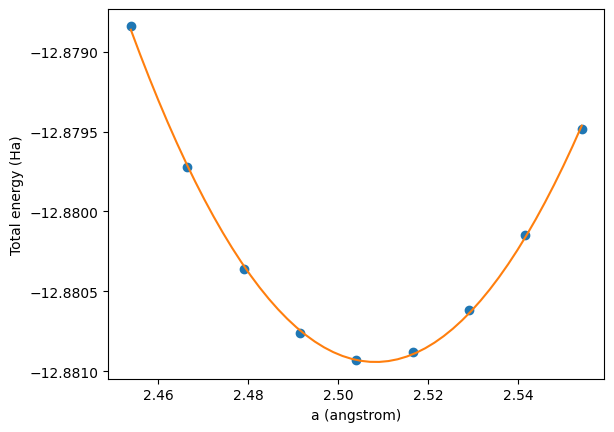

In [15]:
y = [results[ind] for ind in range(len(study.ids))]
x = [alat_ang*(1+a/100) for a in alat_span]
coeffs = np.polyfit(x, y, 2)
x_fit = np.linspace(x[0], x[-1], 50)
plt.plot(x, y, 'o'); plt.plot(x_fit, np.polyval(coeffs, x_fit))
plt.xlabel('a (angstrom)'); plt.ylabel('Total energy (Ha)')
alat_pbe = -coeffs[1]/(2*coeffs[0])
print('PBE equilibrium a = %.4f angstrom (fixed value %.4f)' % (alat_pbe, alat_ang))

### Cell height
The cell height $c$ must be the same for monolayer and bilayer, so it is converged on the bilayer (AA'), which has
the smaller vacuum ($c - d$), and checked on the monolayer. At the DFT level this fixes the spurious interaction
between replicas; with the slab cutoff in GW it will be re-examined there.

In [16]:
c_values = [30, 35, 40, 45, 50]   # bohr

study = D.Dataset(run_dir=run_dir, num_tasks=2)
for s in ['ML', 'AA1']:
    for cval in c_values:
        idd = {'system': s, 'c': cval}
        name = D.name_from_id(idd)
        inp = build_input(s, ecut_conv, k_conv, cval)
        inp.set_prefix(name)
        study.append_run(id=idd, input=inp, runner=code, name=name)
study.set_postprocessing_function(PP.pw_parse_data)

Initialize a Dataset with 2 parallel tasks


In [17]:
results = study.run()

Run the selection [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] with the parallel task_groups [[0, 1], [2, 3], [4, 5], [6, 7], [8, 9]] 

Run the task [0, 1] 


Skip the run of

c_30-system_ML

Skip the run of

c_35-system_ML

Task [0, 1] ended 
 
Run the task [2, 3] 


... (16 outputs left out)

c_45-system_AA1

Skip the run of

c_50-system_AA1

Task [8, 9] ended 
 


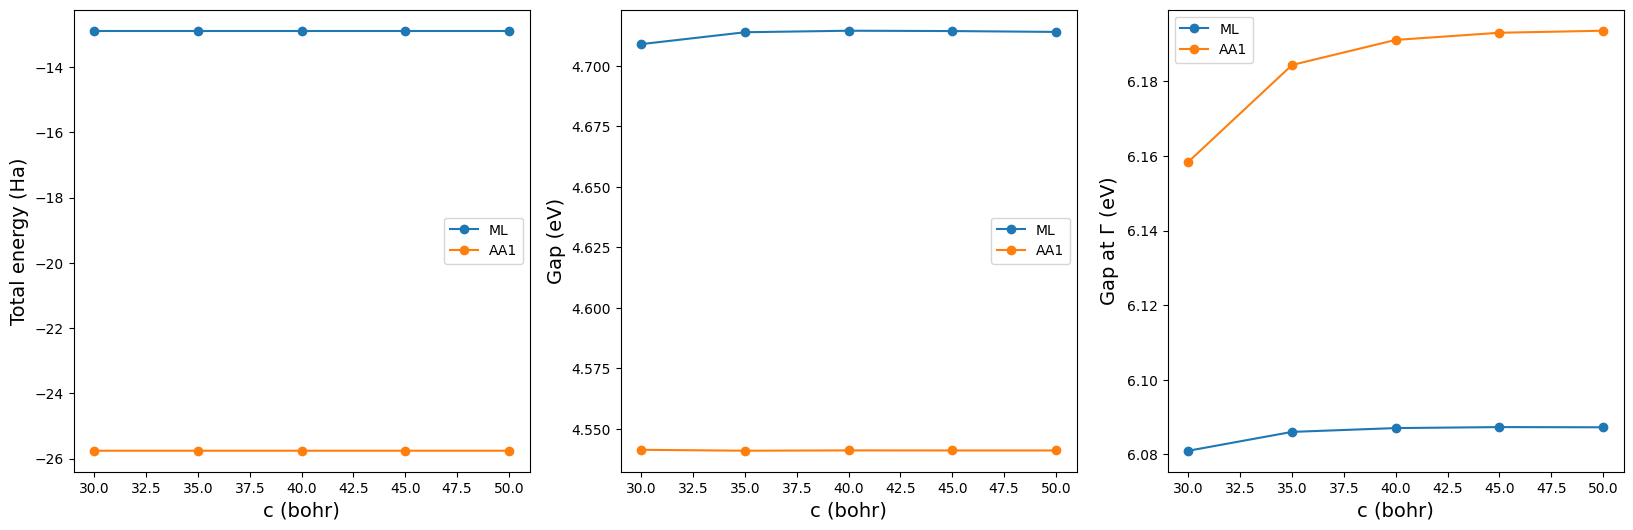

In [18]:
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(20, 6))
for s in ['ML', 'AA1']:
    data = study.fetch_results(id={'system': s})
    ax[0].plot(c_values, [d.energy for d in data], 'o-', label=s)
    ax[1].plot(c_values, [d.get_gap(verbose=False)['gap'] for d in data], 'o-', label=s)
    ax[2].plot(c_values, [gap_gamma(d, s) for d in data], 'o-', label=s)
for a, yl in zip(ax, ['Total energy (Ha)', 'Gap (eV)', r'Gap at $\Gamma$ (eV)']):
    a.set_xlabel('c (bohr)', size=14); a.set_ylabel(yl, size=14); a.legend()

Result: from c = 40 bohr energy, gap and direct gap are stable within 0.5 meV for both ML and AA'. The gap at
$\Gamma$ converges more slowly (the lowest conduction state at $\Gamma$ is a nearly-free-electron state that extends into
the vacuum): 2.4 meV between 40 and 50 bohr for AA'. We choose c = 40 bohr (21.2 Å; vacuum of the bilayer 17.8 Å);
the slab cutoff in GW will be checked separately.

PBE lattice constant (check of the previous section): 2.508 Å, 0.17% above the fixed value 2.504 Å.

In [19]:
c_conv = 40.0   # bohr

### k grid on the bilayers (check)
The k convergence above is done on the monolayer. The bilayers have the CBM at M, so we check them on grids that
contain both K (k multiple of 3) and M (k even): k = 6, 12, 18, 24, at the converged ecut and c.

In [20]:
kvalues_bl = [6, 12, 18, 24]

study = D.Dataset(run_dir=run_dir, num_tasks=2)
for s in ['AA1', 'AB']:
    for k in kvalues_bl:
        idd = {'system': s, 'ecut': ecut_conv, 'k': k, 'c': c_conv}
        name = D.name_from_id(idd)
        inp = build_input(s, ecut_conv, k, c_conv)
        inp.set_prefix(name)
        study.append_run(id=idd, input=inp, runner=code, name=name)
study.set_postprocessing_function(PP.pw_parse_data)
results = study.run()

Initialize a Dataset with 2 parallel tasks
Run the selection [0, 1, 2, 3, 4, 5, 6, 7] with the parallel task_groups [[0, 1], [2, 3], [4, 5], [6, 7]] 

Run the task [0, 1] 


Skip the run of

c_40.0-ecut_80-k_6-system_AA1

Skip the run of

c_40.0-ecut_80-k_12-system_AA1

Task [0, 1] ended 
 
Run the task [2, 3] 


... (11 outputs left out)

c_40.0-ecut_80-k_18-system_AB

Skip the run of

c_40.0-ecut_80-k_24-system_AB

Task [6, 7] ended 
 


AA1 energy (Ha) ['-25.761062', '-25.761078', '-25.761078', '-25.761078']
AA1 gap (eV)    ['4.5414', '4.5412', '4.5411', '4.5266']
AA1 direct (eV) ['4.7653', '4.7649', '4.7649', '4.7360']
AA1 gap at G    ['6.1911', '6.1911', '6.1911', '6.1911']


AB energy (Ha) ['-25.761081', '-25.761102', '-25.761102', '-25.761102']
AB gap (eV)    ['4.5355', '4.5355', '4.5356', '4.5355']
AB direct (eV) ['4.5851', '4.5851', '4.5851', '4.5851']
AB gap at G    ['6.1462', '6.1464', '6.1464', '6.1464']


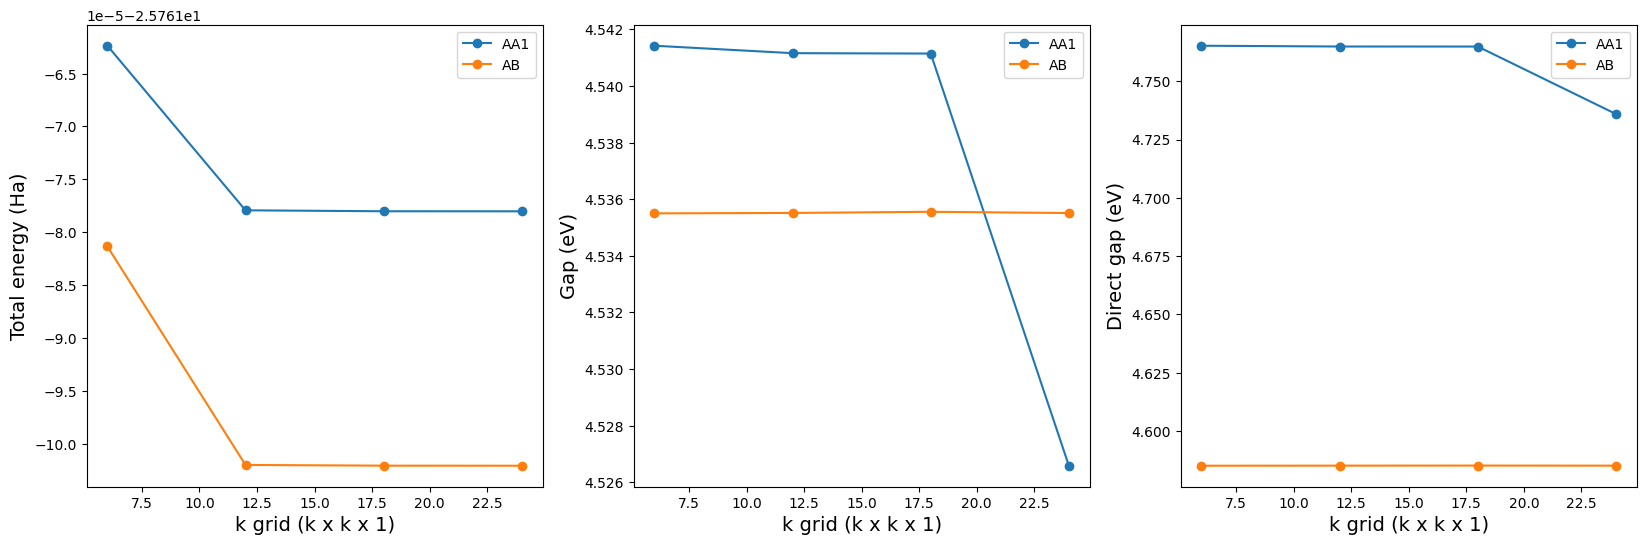

In [21]:
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(20, 6))
for s in ['AA1', 'AB']:
    data = study.fetch_results(id={'system': s})
    g = [d.get_gap(verbose=False) for d in data]
    ax[0].plot(kvalues_bl, [d.energy for d in data], 'o-', label=s)
    ax[1].plot(kvalues_bl, [x['gap'] for x in g], 'o-', label=s)
    ax[2].plot(kvalues_bl, [x['direct_gap'] for x in g], 'o-', label=s)
    print(s, 'energy (Ha)', ['%.6f' % d.energy for d in data])
    print(s, 'gap (eV)   ', ['%.4f' % x['gap'] for x in g])
    print(s, 'direct (eV)', ['%.4f' % x['direct_gap'] for x in g])
    print(s, 'gap at G   ', ['%.4f' % gap_gamma(d, s) for d in data])
for a, yl in zip(ax, ['Total energy (Ha)', 'Gap (eV)', 'Direct gap (eV)']):
    a.set_xlabel('k grid (k x k x 1)', size=14); a.set_ylabel(yl, size=14); a.legend()

Result: the total energy is converged from k = 12 for both bilayers (changes below 1 microHa); AB gaps are stable
within 0.1 meV. AA' gaps are stable up to k = 18 and drop at k = 24 (gap -15 meV, direct gap -29 meV). This is
**not** a convergence problem of the density but a band-edge sampling effect: from the band runs, the VBM of AA' is
NOT at K but slightly off K towards $\Gamma$ (at 0.033 $2\pi/a$ from K, about 5% of $|\Gamma K|$), 29 meV above the value
at K, and the smallest direct gap on the path (4.709 eV) is also slightly off K, on the M-K line. The 24x24 grid is
the first one with a point close to these extrema. In ML and AB the VBM is at K.

Conclusion: k = 12 is converged for the ground state (density, energy) of all systems. The AA' band edges lie off
K: true PBE gaps of AA' about 4.512 eV (indirect, VBM near K -> M) and 4.709 eV (direct, near K), vs 4.541 and
4.765 eV on the grids that contain K. For the benchmark we compare quantities **at K** (high-symmetry point, on
the grid), as planned.

## Bilayer: interlayer distance (optional check)
The production value is fixed, d = 3.33 Å. Here a scan with the DFT-D3 correction (`vdw_corr='dft-d3'`) for AA' and AB
gives the equilibrium distance as a check only.

In [22]:
d_values = [3.0, 3.1, 3.2, 3.3, 3.4, 3.5, 3.6]   # angstrom

study = D.Dataset(run_dir=run_dir, num_tasks=2)
for s in ['AA1', 'AB']:
    for dv in d_values:
        idd = {'system': s, 'd': dv, 'vdw': 'd3'}
        name = D.name_from_id(idd)
        inp = build_input(s, ecut_conv, k_conv, c_conv)
        inp.set_atomic_positions(hbn_positions(s, d_ang=dv), type='alat')
        inp['system']['vdw_corr'] = "'dft-d3'"
        inp.set_prefix(name)
        study.append_run(id=idd, input=inp, runner=code, name=name)
study.set_postprocessing_function(PP.pw_get_energy)

Initialize a Dataset with 2 parallel tasks


In [23]:
results = study.run()

Run the selection [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13] with the parallel task_groups [[0, 1], [2, 3], [4, 5], [6, 7], [8, 9], [10, 11], [12, 13]] 

Run the task [0, 1] 


Skip the run of

d_3.0-system_AA1-vdw_d3

Skip the run of

d_3.1-system_AA1-vdw_d3

Task [0, 1] ended 
 
Run the task [2, 3] 


... (26 outputs left out)

d_3.5-system_AB-vdw_d3

Skip the run of

d_3.6-system_AB-vdw_d3

Task [12, 13] ended 
 


AA1 D3 equilibrium d = 3.443 angstrom


AB D3 equilibrium d = 3.440 angstrom


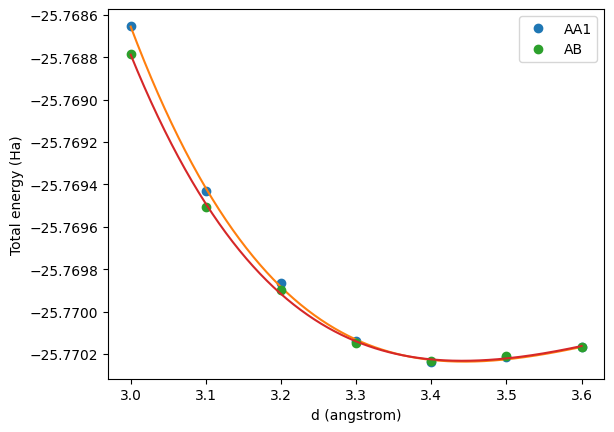

In [24]:
for s in ['AA1', 'AB']:
    y = study.fetch_results(id={'system': s})
    coeffs = np.polyfit(d_values, y, 4)
    x_fit = np.linspace(d_values[0], d_values[-1], 200)
    plt.plot(d_values, y, 'o', label=s); plt.plot(x_fit, np.polyval(coeffs, x_fit))
    print(s, 'D3 equilibrium d = %.3f angstrom' % x_fit[np.argmin(np.polyval(coeffs, x_fit))])
plt.xlabel('d (angstrom)'); plt.ylabel('Total energy (Ha)'); plt.legend()

Result: PBE+D3 gives d = 3.44 Å for both AA' and AB, about 3% above the experimental 3.33 Å used here (kept fixed,
as in Guo et al.).

## Converged ground states
Final scf of the three monolayers (bottom layer, top layer of AA', top layer of AB) and of the two bilayers with
the common converged parameters.

In [25]:
run_dir = 'DFT_analysis'
code = qe_code()

ecut_conv = 80     # Ry (converged values of the previous sections)
k_conv = 12
c_conv = 40.0      # bohr

study = D.Dataset(run_dir=run_dir, num_tasks=2)
for s in systems:
    name = 'gs_converged-%s' % s
    inp = build_input(s, ecut_conv, k_conv, c_conv)
    inp.set_prefix(name)
    study.append_run(id=s, input=inp, runner=code, name=name)
study.set_postprocessing_function(PP.pw_parse_data)

Initialize a QuantumESPRESSO calculator with scheduler slurm
Initialize a Dataset with 2 parallel tasks


In [26]:
results = study.run()

Run the selection [0, 1, 2, 3, 4] with the parallel task_groups [[0, 1], [2, 3], [4]] 

Run the task [0, 1] 


Skip the run of

gs_converged-ML_bot

Skip the run of

gs_converged-ML_top_AA1

Task [0, 1] ended 
 
Run the task [2, 3] 


... (4 outputs left out)

Task [2, 3] ended 
 
Run the task [4] 


Skip the run of

gs_converged-AB

Task [4] ended 
 


In [27]:
gs = {}
for ind, s in enumerate(systems):
    r = results[ind]; gs[s] = r
    g = r.get_gap(verbose=False)
    print(s, 'energy (Ha) = %.6f' % r.energy, '| gap = %.4f eV | direct gap = %.4f eV | gap at Gamma = %.4f eV'
          % (g['gap'], g['direct_gap'], gap_gamma(r, s)))

ML_bot energy (Ha) = -12.880929 | gap = 4.7146 eV | direct gap = 4.7146 eV | gap at Gamma = 6.0871 eV
ML_top_AA1 energy (Ha) = -12.880929 | gap = 4.7145 eV | direct gap = 4.7145 eV | gap at Gamma = 6.0871 eV
ML_top_AB energy (Ha) = -12.880929 | gap = 4.7144 eV | direct gap = 4.7144 eV | gap at Gamma = 6.0870 eV
AA1 energy (Ha) = -25.761078 | gap = 4.5412 eV | direct gap = 4.7649 eV | gap at Gamma = 6.1911 eV
AB energy (Ha) = -25.761102 | gap = 4.5355 eV | direct gap = 4.5851 eV | gap at Gamma = 6.1464 eV


Result (2026-11-11), PBE, common parameters ecut 80 Ry, k 12x12x1, c = 40 bohr, a = 2.504 Å, d = 3.33 Å:

| system | total energy (Ha) | gap (eV) | direct gap (eV) | gap at $\Gamma$ (eV) |
|---|---|---|---|---|
| ML_bot | -12.880929 | 4.7146 (K-K) | 4.7146 | 6.0871 |
| ML_top_AA1 | -12.880929 | 4.7145 | 4.7145 | 6.0871 |
| ML_top_AB | -12.880929 | 4.7144 | 4.7144 | 6.0870 |
| AA' | -25.761078 | 4.5412 (K-M) | 4.7649 | 6.1911 |
| AB | -25.761102 | 4.5355 (K-M) | 4.5851 | 6.1464 |

- The three monolayers agree within 0.2 meV, as expected (same crystal, moved/rotated in the cell).
- AB is lower than AA' by 0.024 mHa per cell (0.65 meV) in plain PBE: the two stackings are degenerate at this level.
- In the monolayer the lowest conduction states at K and at $\Gamma$ (nearly-free-electron state) are almost degenerate
  (4.714 eV from the VBM): the K-K and K-$\Gamma$ gaps differ by less than 1 meV.
- In both bilayers the gap is indirect, K -> M, 0.17-0.18 eV below the monolayer gap.

## Band structures on the path $\Gamma$-M-K-$\Gamma$
Bands of the three systems from the converged ground states. The comparison monolayer vs bilayer measures how much
the ground state of each layer changes in the bilayer (assumption of Notes, Sec. 2.1, on the KS states), and shows
the bonding/antibonding splitting of the degenerate states of the two layers. Bands are aligned at the VBM (an
alignment to the vacuum level can be added later).

In [28]:
G = [0., 0., 0.]
Kp = [1./3., 1./np.sqrt(3), 0.]
Mp = [0., 1./np.sqrt(3), 0.]
high_sym = {'G': G, 'K': Kp, 'M': Mp}
klist = Tools.build_pw_kpath(G, Mp, Kp, G, numstep=60)

band_systems = ['ML_bot', 'AA1', 'AB']
nbnd_bands = {'ML_bot': 12, 'AA1': 24, 'AB': 24}
bands = {}
for s in band_systems:
    name = 'bands-%s' % s
    inp = build_input(s, ecut_conv, k_conv, c_conv)
    inp.set_bands(nbnd_bands[s], force_symmorphic=True, conv_thr=1e-8)
    inp.set_prefix(name)
    inp.set_kpoints(type='tpiba_b', klist=klist)
    res = code.run(input=inp, run_dir=run_dir, name=name, source_dir='%s/gs_converged-%s.save' % (run_dir, s))
    bands[s] = U.BandStructure.from_Pw(res, high_sym)

Skip the run of bands-ML_bot
The folder /work/dalessandro/2d-layer-substrate-effective-screening/hBN_bilayer/DFT_analysis/bands-ML_bot.save already exists. Source_dir DFT_analysis/gs_converged-ML_bot.save not copied
Skip the run of bands-AA1
The folder /work/dalessandro/2d-layer-substrate-effective-screening/hBN_bilayer/DFT_analysis/bands-AA1.save already exists. Source_dir DFT_analysis/gs_converged-AA1.save not copied
Skip the run of bands-AB
The folder /work/dalessandro/2d-layer-substrate-effective-screening/hBN_bilayer/DFT_analysis/bands-AB.save already exists. Source_dir DFT_analysis/gs_converged-AB.save not copied


Text(0, 0.5, 'Band structure (eV)')

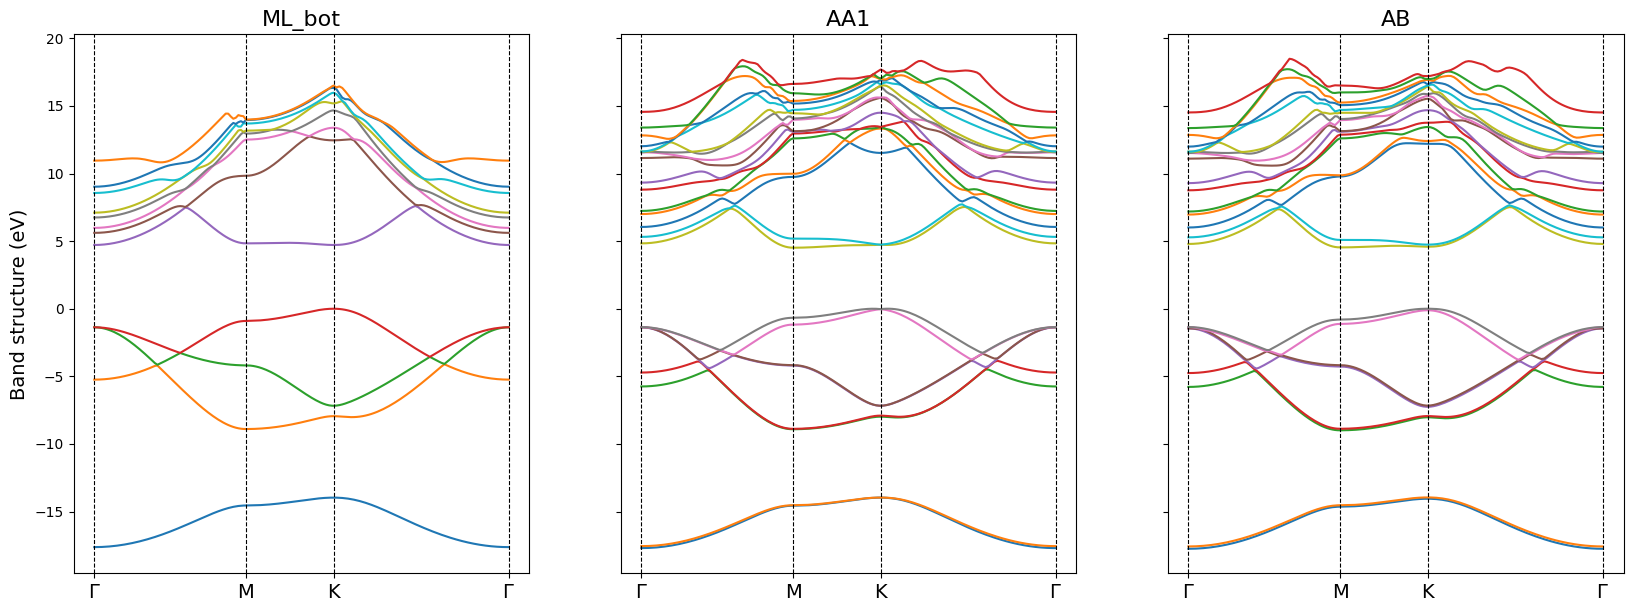

In [29]:
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(20, 7), sharey=True)
for a, s in zip(ax, band_systems):
    bands[s].plot(plt, axes=a)
    a.set_title(s, size=16)
ax[0].set_ylabel('Band structure (eV)', size=14)

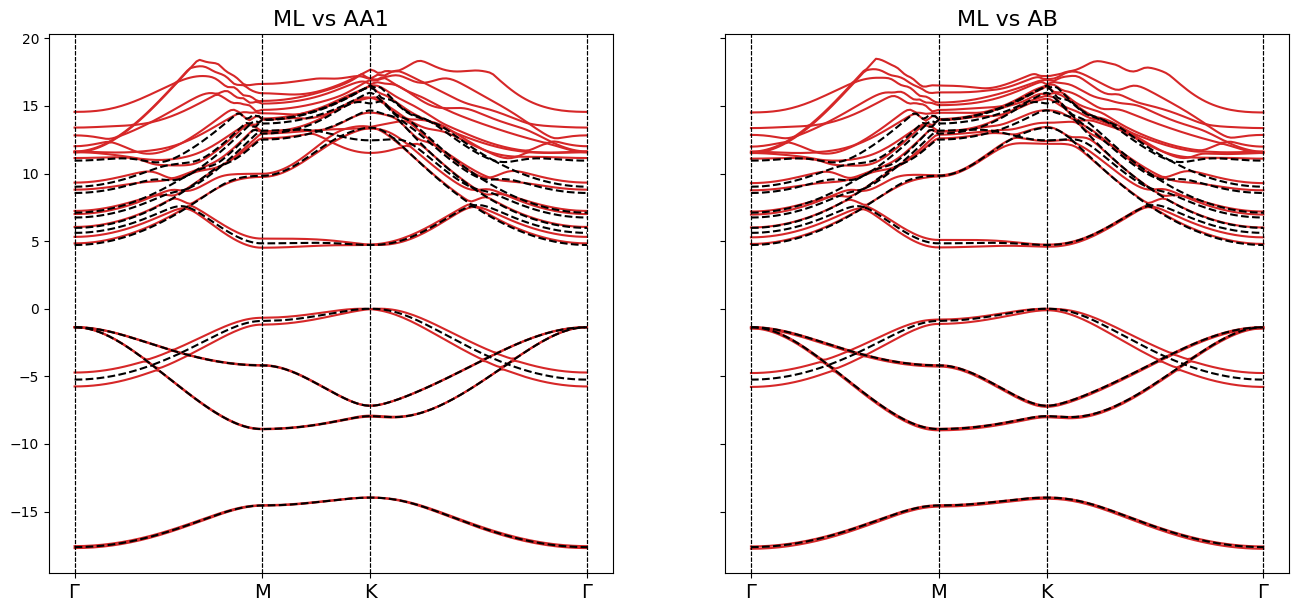

In [30]:
# Overlay monolayer vs bilayers
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 7), sharey=True)
for a, s in zip(ax, ['AA1', 'AB']):
    bands[s].plot(plt, axes=a, color='tab:red', label=s)
    bands['ML_bot'].plot(plt, axes=a, color='black', linestyle='--', label='ML')
    a.set_title('ML vs %s' % s, size=16)

Result: band energies (eV, from the VBM) at the high-symmetry points, from the band runs:

| | ML | AA' | AB |
|---|---|---|---|
| top valence at K | 0.000 | -0.029, -0.029 | -0.113, 0.000 |
| lowest conduction at K | 4.714 | 4.736, 4.736 | 4.585, 4.741 |
| top valence at M | -0.905 | -1.173, -0.670 | -1.123, -0.803 |
| lowest conduction at M | 4.834 | 4.513, 5.185 | 4.535, 5.088 |
| lowest conduction at $\Gamma$ | 4.714 | 4.833, 5.314 | 4.791, 5.278 |

- **At K** the AA' states stay pairwise degenerate (no splitting, inversion symmetry and weak coupling of the
  K states): the direct gap at K changes by only +22 meV with respect to the monolayer. In AB the two layers are not
  equivalent and the K states split by 0.11 eV (valence) and 0.16 eV (conduction): direct gap 4.585 eV.
- **At M and $\Gamma$** the $\pi$/$\pi^*$ states and the nearly-free-electron states of the two layers hybridize strongly
  (bonding/antibonding splitting of 0.5 eV for the top valence at M, 0.67 eV for the lowest conduction at M, 0.5 eV
  for the NFE states at $\Gamma$). The bilayer CBM moves to M and the gap becomes indirect (K -> M), 0.17 eV below the
  monolayer gap: this reduction is a ground-state hybridization effect, NOT a screening effect.
- Consequence for the benchmark: the assumption of no overlap between the states of the two layers (Notes,
  Sec. 2.1) holds well for the states at K in AA' and fails for the conduction states at M and $\Gamma$ (and for the
  empty states that enter chi0). The explicit vs effective GW comparison must therefore focus on the quasiparticle
  corrections at K (AA' first), and the DFT differences between ML and BL must be kept separate from the
  screening contribution. The deeper valence bands are unchanged (within ~0.1 eV).

## AB bilayer: dipole correction (check)
The AB bilayer has an out-of-plane dipole: in the periodic cell it produces a spurious field across the vacuum.
We repeat the AB scf with the dipole correction of pw.x (`tefield`, `dipfield`, sawtooth in the vacuum region,
`edir=3`; the layers sit at crystal z ~ ±0.08, the sawtooth at 0.5-0.6) and compare energy and gaps. The
correction is only a check: the yambo databases are built without it unless the effect is relevant.

In [31]:
study = D.Dataset(run_dir=run_dir, num_tasks=1)
name = 'gs_converged-AB-dipfield'
inp = build_input('AB', ecut_conv, k_conv, c_conv)
inp['control']['tefield'] = '.true.'
inp['control']['dipfield'] = '.true.'
inp['system']['edir'] = 3
inp['system']['emaxpos'] = 0.5
inp['system']['eopreg'] = 0.1
inp['system']['eamp'] = 0.0
inp.set_prefix(name)
study.append_run(id='AB-dipfield', input=inp, runner=code, name=name)
study.set_postprocessing_function(PP.pw_parse_data)
results = study.run()

Initialize a Dataset with 1 parallel tasks
Run the selection [0] with the parallel task_groups [[0]] 

Run the task [0] 


Skip the run of

gs_converged-AB-dipfield

Task [0] ended 
 


In [32]:
r = results[0]
g, g0 = r.get_gap(verbose=False), gs['AB'].get_gap(verbose=False)
print('AB with dipole correction: energy %.6f Ha, gap %.4f eV, direct gap %.4f eV' % (r.energy, g['gap'], g['direct_gap']))
print('AB without               : energy %.6f Ha, gap %.4f eV, direct gap %.4f eV' % (gs['AB'].energy, g0['gap'], g0['direct_gap']))

AB with dipole correction: energy -25.761102 Ha, gap 4.5308 eV, direct gap 4.5772 eV
AB without               : energy -25.761102 Ha, gap 4.5355 eV, direct gap 4.5851 eV


Result: the AB bilayer has a small dipole along z (0.0155 Debye per cell, electronic and ionic dipoles of about
1.32 Debye almost cancel each other); the dipole correction changes the total energy by less than 1 microHa and
the gaps by 5-8 meV (gap 4.5308 eV, direct gap 4.5772 eV). The correction is negligible at this level: the Yambo
databases can be built without it.

## Density profile along z and the slab cutoff of Yambo
The slab cutoff of Yambo (`CUTGeo='slab z'`, `cutoff_slab.F`, see `docs/02_...`, Sec. 4 B) truncates the Coulomb
interaction for $|z-z'| > L/2$ ($L$ = cell height): it is translation invariant along z (the position of the layers
in the cell does not matter), but it is correct only if the whole system, both layers for the bilayer, lies within a
window of width $L/2$ = 10.58 Å. We check it on the planar-averaged valence density computed with the QE tools:
`pp.x` (`plot_num = 0`, valence charge density) and `average.x` (planar average along z, direction 3).

Both run in one slurm job (1 node; `sbatch --wait`, the cell waits for the end of the job) in
`DFT_analysis/density_profile/`, starting from the converged ground states. Systems whose profile `avg_<system>.dat`
already exists are skipped. With Intel MPI the QE tools do not read redirected stdin: `average.x -inp`.

In [33]:
import subprocess

prof_dir = os.path.join(run_dir, 'density_profile')
prof_systems = ['ML_bot', 'AA1', 'AB']
nz_avg = 800      # points of the planar average along z

def write_density_profile_inputs(system):
    # pp.x: valence charge density of the converged ground state; average.x: planar average along z
    with open(os.path.join(prof_dir, 'pp_%s.in' % system), 'w') as f:
        f.write("&inputpp\n  prefix = 'gs_converged-%s'\n  outdir = '../'\n  filplot = 'rho_%s.dat'\n  plot_num = 0\n/\n"
                % (system, system))
    with open(os.path.join(prof_dir, 'avg_%s.in' % system), 'w') as f:
        # nfile, file, weight, number of points, direction (3 = z), window of the macroscopic average (bohr, > 0)
        f.write('1\nrho_%s.dat\n1.0\n%d\n3\n1.0\n' % (system, nz_avg))

def run_density_profiles(systems, partition='all12h'):
    os.makedirs(prof_dir, exist_ok=True)
    todo = [s for s in systems if not os.path.isfile(os.path.join(prof_dir, 'avg_%s.dat' % s))]
    if not todo:
        print('density profiles already computed'); return
    for s in todo: write_density_profile_inputs(s)
    lines = ['#!/bin/bash', '#SBATCH --job-name=density_profile', '#SBATCH --partition=%s' % partition,
             '#SBATCH --nodes=1', '#SBATCH --ntasks-per-node=4', '#SBATCH --time=00:30:00',
             '#SBATCH --output=job_density_profile.out', 'source %s' % module]
    for s in todo:
        lines += ['mpirun -np 4 pp.x -inp pp_%s.in > pp_%s.log' % (s, s),
                  'mpirun -np 1 average.x -inp avg_%s.in > avg_%s.log && mv avg.dat avg_%s.dat' % (s, s, s)]
    with open(os.path.join(prof_dir, 'job_density_profile.sh'), 'w') as f: f.write('\n'.join(lines) + '\n')
    print('run pp.x + average.x for', todo)
    subprocess.run(['sbatch', '--wait', 'job_density_profile.sh'], cwd=prof_dir, check=True)
    for s in todo:
        if not os.path.isfile(os.path.join(prof_dir, 'avg_%s.dat' % s)): print('WARNING: no profile for', s)

def read_density_profile(system, c=c_conv):
    # planar-averaged valence density (e/bohr^3) vs z (angstrom), with z in (-c/2, c/2]: the cell origin at the centre
    z, rho, _ = np.loadtxt(os.path.join(prof_dir, 'avg_%s.dat' % system)).T   # z in bohr, from 0 to c
    z = np.where(z >= c/2, z - c, z); o = np.argsort(z)
    return z[o]*Const.Bohr_to_Angstrom, rho[o]

run_density_profiles(prof_systems)

run pp.x + average.x for ['ML_bot', 'AA1', 'AB']
Submitted batch job 60780


ML_bot  8.0000 electrons; rho > 1e-4 max for z in [-4.71, 1.38] A (width 6.09 A); charge outside the L/2 window: 2.1e-08; weight of the pairs with |z - z'| > L/2: 1.3e-15
AA1     16.0000 electrons; rho > 1e-4 max for z in [-4.71, 4.71] A (width 9.42 A); charge outside the L/2 window: 3.3e-06; weight of the pairs with |z - z'| > L/2: 1.1e-10
AB      16.0000 electrons; rho > 1e-4 max for z in [-4.71, 4.71] A (width 9.42 A); charge outside the L/2 window: 3.5e-06; weight of the pairs with |z - z'| > L/2: 1.1e-10


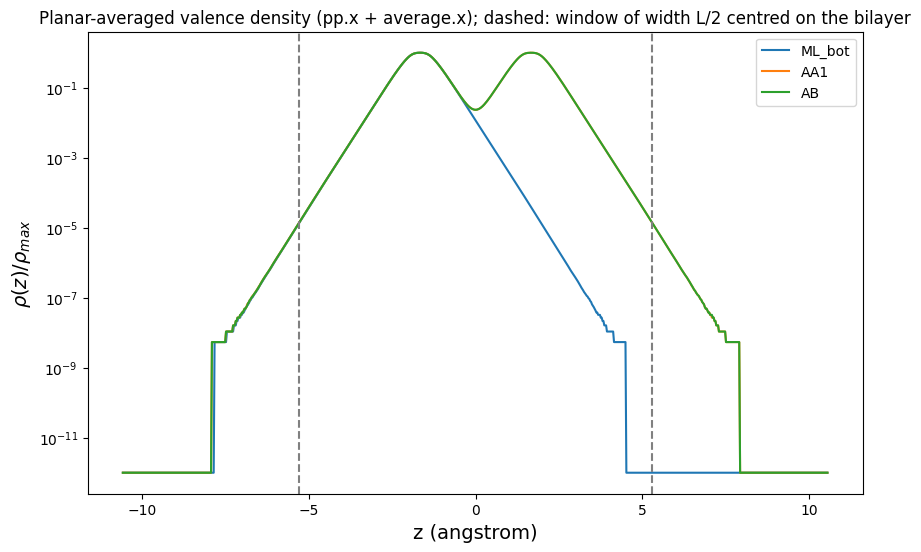

In [34]:
Lz = c_conv*Const.Bohr_to_Angstrom          # cell height in angstrom
area = (alat**2)*np.sqrt(3)/2               # cell area in bohr^2
fig, ax = plt.subplots(figsize=(10, 6))
for s in prof_systems:
    z, rho = read_density_profile(s)
    nel = rho.sum()*(z[1] - z[0])/Const.Bohr_to_Angstrom*area
    w = np.clip(rho, 0, None); w /= w.sum(); zc = (w*z).sum()
    zz = (z - zc + Lz/2) % Lz - Lz/2                      # coordinates in the cell centred on the system
    dz = np.abs(zz[:, None] - zz[None, :])
    m = rho > 1e-4*rho.max()
    print("%-7s %.4f electrons; rho > 1e-4 max for z in [%.2f, %.2f] A (width %.2f A); charge outside the L/2 window:"
          " %.1e; weight of the pairs with |z - z'| > L/2: %.1e"
          % (s, nel, z[m].min(), z[m].max(), z[m].max() - z[m].min(), w[np.abs(zz) > Lz/4].sum(),
             np.outer(w, w)[dz > Lz/2].sum()))
    ax.semilogy(z, np.clip(rho/rho.max(), 1e-12, None), label=s)
for x in [-Lz/4, Lz/4]: ax.axvline(x, color='gray', ls='--')
ax.set_xlabel('z (angstrom)', size=14); ax.set_ylabel(r'$\rho(z)/\rho_{max}$', size=14)
ax.set_title('Planar-averaged valence density (pp.x + average.x); dashed: window of width L/2 centred on the bilayer')
ax.legend()

Result: the planar averages integrate to 8 (monolayer) and 16 (bilayers) electrons. The density of the bilayers
falls below $10^{-4}$ of its maximum within $|z| < 4.7$ Å (width 9.4 Å) and below $10^{-5}$ within 5.4 Å; the charge
outside the window of width $L/2$ is about $3\times10^{-6}$ of the total and the weight of the pairs of charges at
$|z-z'| > L/2$, whose interaction the cutoff gets wrong, is about $10^{-10}$. With c = 40 bohr the slab cutoff is safe
for both bilayers and for the monolayers (in any position in the cell). The nearly-free-electron empty states
extend further into the vacuum, but in chi0 every term contains an occupied state at r and at r' (Notes,
Sec. 2.1), so the occupied density is the relevant one.

## NSCF on regular grids (for Yambo)
To be set up with the GW analysis (k grids, number of bands, folders for the SAVE databases): same grids and bands
for monolayer and bilayers.

Status (2026-11-11): converged ground states for ML_bot, ML_top_AA1, ML_top_AB, AA' and AB are in
`DFT_analysis/gs_converged-<system>.save`; the nscf runs (k grids, number of bands) will be defined with the GW
convergence (`GW_Analysis.ipynb`), with the same grids and bands for monolayers and bilayers.